<a href="https://colab.research.google.com/github/yufree/OSSpRe/blob/main/OSSpRe_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OSSpRe Full Workflow (Colab / Linux, real Bruker data)

This notebook runs the **complete OSSpRe workflow** on a real Bruker MALDI-TIMS
`.d` dataset, from raw data through molecular networking, on a Linux CPU
runtime. The R environment is restored strictly from the repository's
`renv.lock` (R 4.6.1, 178 packages; `opentimsr` comes from the author's drat
repository). **No rpy2** — every R step runs in its own `Rscript` process, so
there is no embedded-R initialization to crash.

**Pipeline** (mirrors `workflow.Rmd`, section by section):

| # | Step | Input -> output |
|---|------|-----------------|
| 0 | Mount Drive, copy the `.d` to local disk | `.d` |
| 1 | `getrefpeak` super pixel + reference peaks | `refpeak.csv`, `coord.csv` |
| 2 | `find_2d_peaks` 2D reference peak picking | `ref2d.csv` |
| 3 | `getqlist` quantitative peak list (TIC/RMS normalised) | `ticmzccs.csv` |
| 4 | `getanno` lipid + metabolite annotation | `annoccs.csv`, `metaannoccs.csv` |
| 5 | Exploratory analysis: summary, peak statistics, ion images, PCA + UMAP segmentation, ion clustering, ROI clustering, reactomics | PNGs + csv |
| 6 | Molecular network + MSInet table | `molecular_network.csv`, `msinet.csv` |

**Usage**: open directly in Colab

`https://colab.research.google.com/github/yufree/OSSpRe/blob/main/OSSpRe_workflow.ipynb`

Use a default CPU runtime, then **Run all**. Step 0 asks for Drive
authorization. The environment restore (step 0b) is the long part
(**~30-50 minutes**, mostly Bioconductor source compilation); the data steps
add roughly 10-40 minutes depending on how many pixels fall in the ROI. Keep
the tab open to avoid disconnects.

Everything after the environment section is driven by `/content/config.R` —
edit that one cell to point at your own `.d`, ROI and peak-picking parameters.

## Step 0. Mount Google Drive and stage the raw data

The demo dataset is a Bruker `.d` folder (a folder, not a single file) in your
Drive. We copy it to local disk first: Colab's Drive backend is slow for the
many small reads that TIMS frame queries perform.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil

# --- point this at your own Bruker .d folder ---
SRC = '/content/drive/MyDrive/2023-07-28_SS_Panc_Lipids_38596.d'
DST = '/content/2023-07-28_SS_Panc_Lipids_38596.d'

if not os.path.isdir(SRC):
    raise FileNotFoundError(
        f'{SRC} not found. Upload your .d folder to Google Drive and edit SRC.')

if os.path.isdir(DST):
    print('raw data already staged at', DST)
else:
    print('copying .d folder to local disk ...')
    shutil.copytree(SRC, DST)

# the .d is a folder with an analysis.tdf SQLite file + frame files
print('staged:', sorted(os.listdir(DST))[:6], '...')

Mounted at /content/drive
copying .d folder to local disk ...
staged: ['analysis.tdf', 'analysis.tdf_bin', 'lipids tims on imaging 10 um pos_100msTIMS.m'] ...


## Step 0b. Install R 4.6.1 and restore the R environment

Same setup as the verification notebook: system libraries, Posit r-builds
**R 4.6.1** (matching `renv.lock`), then a shallow clone of this repository and
`renv::restore()`. If this cell is interrupted, **just re-run it** — renv only
installs the missing packages.

In [2]:
%%bash
# ---- system libraries + R 4.6.1 from Posit r-builds, ~3 min ----
set -e
apt-get update -qq
PKGS="build-essential gfortran git curl ca-certificates \
  libcurl4-openssl-dev libssl-dev libxml2-dev libzstd-dev \
  libfontconfig1-dev libfreetype6-dev pkg-config libpng-dev libtiff-dev \
  libjpeg-dev libnetcdf-dev libgit2-dev libglpk-dev libharfbuzz-dev \
  libfribidi-dev libcairo2-dev libxt-dev libblas-dev liblapack-dev"
DEBIAN_FRONTEND=noninteractive apt-get install -y --no-install-recommends $PKGS \
  > /tmp/apt.log 2>&1 || { echo "some system packages failed, continuing..."; tail -5 /tmp/apt.log; }
# build deps some R packages need when compiling from source
DEBIAN_FRONTEND=noninteractive apt-get install -y --no-install-recommends \
  libglpk-dev libgmp3-dev libuv1-dev >> /tmp/apt.log 2>&1 || true

. /etc/os-release
case "$VERSION_CODENAME" in
  noble) UB=2404 ;;
  *)     UB=2204 ;;
esac
echo "$VERSION_CODENAME" > /content/codename
echo "Ubuntu $VERSION_CODENAME -> ubuntu-$UB"
if curl -fsSL -o /tmp/r.deb "https://cdn.posit.co/r/ubuntu-${UB}/pkgs/r-4.6.1_1_amd64.deb" \
   && DEBIAN_FRONTEND=noninteractive apt-get install -y /tmp/r.deb >> /tmp/apt.log 2>&1; then
  ln -sf /opt/R/4.6.1/bin/R /usr/local/bin/R
  ln -sf /opt/R/4.6.1/bin/Rscript /usr/local/bin/Rscript
  echo "installed r-builds R 4.6.1 (matches renv.lock)"
else
  echo "warning: r-builds install failed, falling back to apt r-base"
  DEBIAN_FRONTEND=noninteractive apt-get install -y r-base r-base-dev >> /tmp/apt.log 2>&1
fi
R --version | head -1
nproc

Ubuntu noble -> ubuntu-2404
installed r-builds R 4.6.1 (matches renv.lock)
R version 4.6.1 (2026-06-24) -- "Happy Hop"
8


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [3]:
%%bash
set -e
cd /content
rm -rf OSSpRe
git clone --depth 1 https://github.com/yufree/OSSpRe.git
cd OSSpRe
git log --oneline -1
grep -q "roi_idx" helper.r \
  && echo "code fixes included" \
  || { echo "error: cloned repository is missing the fixes"; exit 1; }
grep -q "yufree.github.io/drat" renv.lock \
  && echo "renv.lock points to the drat repository" \
  || { echo "error: renv.lock does not point to drat"; exit 1; }
# optional python deps for the workflow (UMAP + official Bruker dynamic library)
pip install -q umap-learn opentims-bruker-bridge
echo "clone ready"

b35e44f Support full super-pixel 2D peak picking to recover all 71,895 reference candidate peaks
code fixes included
renv.lock points to the drat repository
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 16.2 MB/s eta 0:00:00
clone ready


Cloning into 'OSSpRe'...


In [4]:
%%writefile /content/setup_env.R
# Restore the environment from renv.lock (standalone R process, no rpy2 needed)
# Force source builds: some P3M binaries are broken on the current Colab image
Sys.setenv(RENV_CONFIG_TYPE = "source")
options(renv.config.type = "source")

codename <- tryCatch(readLines("/content/codename", warn = FALSE), error = function(e) "jammy")
repos <- c(P3Mbin   = sprintf("https://packagemanager.posit.co/all/__linux__/%s/latest", codename),
           drat     = "https://yufree.github.io/drat",
           CRAN     = "https://cloud.r-project.org",
           BioCsoft = "https://bioconductor.org/packages/3.23/bioc")
options(repos = repos)
if (!requireNamespace("renv", quietly = TRUE)) install.packages("renv", repos = repos[1])

setwd("/content/OSSpRe")
source("renv/activate.R")
cat("R:", as.character(getRversion()), "| project library:", unlist(.libPaths())[1], "\n")

t0 <- Sys.time()
# rebuild stringi explicitly: its prebuilt binary has bitten us before
cat("compiling stringi from source...\n")
try(renv::install("stringi", rebuild = TRUE, prompt = FALSE))

renv::restore(prompt = FALSE, repos = repos)
cat(sprintf("renv::restore finished in %.1f minutes\n",
            as.numeric(difftime(Sys.time(), t0, units = "mins"))))

need <- c("Rcpp", "data.table", "opentimsr", "pmd", "rmwf", "enviGCMS",
          "irlba", "ClusterR", "umap", "reticulate")
got <- sapply(need, requireNamespace, quietly = TRUE)
print(got)
stopifnot(all(got))
cat("environment ready\n")

Writing /content/setup_env.R


In [5]:
%%bash
# ~30-50 minutes (Bioconductor source compilation); re-run to resume if interrupted
export RENV_CONFIG_INSTALL_TRANSACTIONAL=FALSE
Rscript /content/setup_env.R

# Bootstrapping renv 1.3.1 ---------------------------------------------------
- Downloading renv ... OK
- Installing renv  ... OK

- One or more packages recorded in the lockfile are not installed.
- Use `renv::status()` for more details.
R: 4.6.1 | project library: /content/OSSpRe/renv/library/linux-ubuntu-noble/R-4.6/x86_64-pc-linux-gnu 
compiling stringi from source...
The following package(s) will be installed:
- stringi [1.8.9]
These packages will be installed into "/content/OSSpRe/renv/library/linux-ubuntu-noble/R-4.6/x86_64-pc-linux-gnu".

# Downloading packages -------------------------------------------------------
✔ stringi 1.8.9                            [3.5 MB in 0.79s]
Successfully downloaded 1 package in 1 second.

# Installing packages --------------------------------------------------------
✔ stringi 1.8.9                            [installed binary]
The following package(s) will be updated:

# Bioconductor 3.23 ------------------------------------------------------

trying URL 'https://packagemanager.posit.co/all/__linux__/noble/latest/src/contrib/renv_1.3.1.tar.gz'
Content type 'binary/octet-stream' length 2748432 bytes (2.6 MB)
downloaded 2.6 MB

* installing *binary* package ‘renv’ ...
* package ‘renv’ successfully unpacked and SHA256 sums checked
* DONE (renv)

The downloaded source packages are in
	‘/tmp/RtmpdlNSAF/downloaded_packages’
Updating HTML index of packages in '.Library'
Making 'packages.html' ... done


## Step 0c. Shared configuration

Every workflow step sources this one file. Change the raw-data path, ROI,
peak-picking and clustering parameters here — nothing else needs editing.

- `XRANGE`/`YRANGE` are the pixel-index ROI; `workflow.Rmd` uses
  `c(3400,3900)` x `c(1050,1600)` for this dataset, so the notebook follows
  suit. Widen them to `c(0,1e9)` to use the whole sample.
- `rcpp.cache.dir` points outside the repo so the three C++ files are compiled
  **once** and reused by every later `Rscript` step.

In [14]:
%%writefile /content/config.R
# ------------------------------------------------------------------
# Shared configuration for the OSSpRe workflow.
# Outputs are written into /content/OSSpRe (throwaway in Colab).
# ------------------------------------------------------------------

# raw Bruker .d folder staged by the Drive cell
RAW_PATH       <- "/content/2023-07-28_SS_Panc_Lipids_38596.d"
BRUKER_LIBPATH <- "/content/bruker/"                    # libtimsdata.so download dir
LIB_PATH       <- file.path(BRUKER_LIBPATH, "libtimsdata.so")

# region of interest in pixel indices (values from workflow.Rmd for this dataset)
XRANGE <- c(3400, 3900)
YRANGE <- c(1050, 1600)

# super-pixel / 2D peak picking
BATCH_SIZE    <- 25000  # 25,000 frames/batch: optimal for 50GB High-RAM
MZ_PPM        <- 20
CCS_TOLERANCE <- 0.03
SNR           <- 10
MZ_BINS       <- 20000
CCS_BINS      <- 250

# quantitative peak list
METHOD                 <- "tic"   # "tic" or "rms"
ZERO_PROPORTION_CUTOFF <- 0.95

# annotation
ION_MODE <- "pos"                 # "pos" or "neg"

# ion clustering
HCLUST_CUTOFF    <- 0.6
MIN_CLUSTER_SIZE <- 10

# compile the C++ helpers once and reuse them across Rscript steps
options(rcpp.cache.dir = "/content/rcpp_cache")

if (!dir.exists(BRUKER_LIBPATH)) dir.create(BRUKER_LIBPATH, recursive = TRUE)
if (!file.exists(LIB_PATH)) {
  # extract from python bridge if installed
  try({
    py_lib <- system("python3 -c 'import opentims_bruker_bridge, pathlib; print(pathlib.Path(opentims_bruker_bridge.__file__).parent / \"libtimsdata.so\")'", intern = TRUE)
    if (file.exists(py_lib)) file.copy(py_lib, LIB_PATH)
  }, silent = TRUE)
  if (!file.exists(LIB_PATH)) {
    cat('Downloading Bruker proprietary code into', BRUKER_LIBPATH, '...\n')
    tryCatch(opentimsr::download_bruker_proprietary_code(BRUKER_LIBPATH), error = function(e) warning(conditionMessage(e)))
  }
}
if (!dir.exists(RAW_PATH))
  stop("raw .d folder not found: ", RAW_PATH, " -- run the Drive mount cell first")
cat("raw data :", RAW_PATH, "\n")
cat("ROI      : X", XRANGE[1], "-", XRANGE[2], "| Y", YRANGE[1], "-", YRANGE[2], "\n")
cat("normalise:", METHOD, "| zero cutoff:", ZERO_PROPORTION_CUTOFF, "\n")

Overwriting /content/config.R


## Step 1. Raw data -> super pixel -> reference peaks

`getrefpeak` downloads Bruker's `libtimsdata.so` (accepting the EULA), sums all
pixels in the ROI into one super pixel, and writes the summed m/z, CCS and
intensity bins (`refpeak.csv`) plus the pixel coordinates (`coord.csv`).

In [15]:
%%writefile /content/workflow_01_refpeak.R
setwd("/content/OSSpRe")
source("renv/activate.R")
source("/content/config.R")
suppressPackageStartupMessages(source("helper.r"))

t0 <- Sys.time()
getrefpeak(
  path      = RAW_PATH,
  accept_Bruker_EULA_and_on_Windows_or_Linux = TRUE,
  libpath   = BRUKER_LIBPATH,
  batch_size = BATCH_SIZE,
  outref    = "refpeak.csv",
  outcoord  = "coord.csv",
  xrange    = XRANGE,
  yrange    = YRANGE
)
cat(sprintf("super pixel written (%.1f min)\n",
            as.numeric(difftime(Sys.time(), t0, units = "mins"))))
cat("super-pixel bins:", nrow(fread("refpeak.csv")),
    "| pixels in ROI:", nrow(fread("coord.csv")), "\n")

Overwriting /content/workflow_01_refpeak.R


In [8]:
%%bash
cd /content/OSSpRe
Rscript /content/workflow_01_refpeak.R

raw data : /content/2023-07-28_SS_Panc_Lipids_38596.d 
ROI      : X 3400 - 3900 | Y 1050 - 1600 
normalise: tic | zero cutoff: 0.95 
super pixel written (6.1 min)
super-pixel bins: 108160677 | pixels in ROI: 127813 


## Step 2. Reference peak picking

`find_2d_peaks` runs 2D peak picking on the super pixel (m/z x CCS). The
default keeps every local maximum; an optional intensity cutoff (kept
commented, as in `workflow.Rmd`) trims weak peaks before step 3 to save time.

In [16]:
%%writefile /content/workflow_02_refpeaks.R
setwd("/content/OSSpRe")
source("renv/activate.R")
source("/content/config.R")
suppressPackageStartupMessages(source("helper.r"))

dtx <- fread("refpeak.csv")
result <- find_2d_peaks(dtx$mz, dtx$ccs, dtx$intensity,
                        MZ_PPM, CCS_TOLERANCE, SNR, MZ_BINS, CCS_BINS)
fwrite(result, "ref2d.csv")
cat("super-pixel bins:", nrow(dtx), "-> reference peaks:", nrow(result), "\n")

# optional: keep only peaks above the mean reference intensity
# sub <- result[result$intensity > mean(result$intensity), ]
# fwrite(sub, "ref2d.csv")
sub <- result[result$intensity > mean(result$intensity), ]
cat("peaks above mean intensity:", nrow(sub),
    "(uncomment the cutoff block to keep only these)\n")

Overwriting /content/workflow_02_refpeaks.R


In [17]:
%%bash
cd /content/OSSpRe
Rscript /content/workflow_02_refpeaks.R

raw data : /content/2023-07-28_SS_Panc_Lipids_38596.d 
ROI      : X 3400 - 3900 | Y 1050 - 1600 
normalise: tic | zero cutoff: 0.95 
super-pixel bins: 108160677 -> reference peaks: 71632 
peaks above mean intensity: 3342 (uncomment the cutoff block to keep only these)


## Step 3. Quantitative peak list

`getqlist` re-reads the raw frames, matches every ion against the reference
list with `findpeakalign`, normalises per pixel (TIC by default) and drops
peaks that are zero in more than `ZERO_PROPORTION_CUTOFF` of pixels. Output
`ticmzccs.csv` has `location` (`X_Y`) first, then one column per ion named
`mz_ccs`.

In [20]:
%%writefile /content/workflow_03_qlist.R
setwd("/content/OSSpRe")
source("renv/activate.R")
source("/content/config.R")
suppressPackageStartupMessages(source("helper.r"))

t0 <- Sys.time()
getqlist(
  refpath   = "ref2d.csv",
  lib_path  = LIB_PATH,
  path      = RAW_PATH,
  method    = METHOD,
  zero_proportion_cutoff = ZERO_PROPORTION_CUTOFF,
  coordpath = "coord.csv",
  normpath  = "ticmzccs.csv",
  xrange    = XRANGE,
  yrange    = YRANGE,
  mz_ppm    = MZ_PPM,
  ccs_tolerance = CCS_TOLERANCE,
  batch_size = BATCH_SIZE
)
cat(sprintf("quantitative peak list written (%.1f min)\n",
            as.numeric(difftime(Sys.time(), t0, units = "mins"))))
dt <- fread("ticmzccs.csv")
cat("pixels:", nrow(dt), "| ions retained:", ncol(dt) - 1, "\n")

Overwriting /content/workflow_03_qlist.R


In [21]:
%%bash
cd /content/OSSpRe
Rscript /content/workflow_03_qlist.R

raw data : /content/2023-07-28_SS_Panc_Lipids_38596.d 
ROI      : X 3400 - 3900 | Y 1050 - 1600 
normalise: tic | zero cutoff: 0.95 
quantitative peak list written (33.4 min)
pixels: 127813 | ions retained: 6439 


## Step 4. Qualitative peak list — annotation

`getanno` aligns the reference ions against the bundled MS1-CCS databases
(`lipidall.csv` and `metaall.csv`, both shipped in the repository) at
20 ppm m/z / ±5 Å² absolute CCS (≈1.5–2.6% relative).

In [22]:
%%writefile /content/workflow_04_annotate.R
setwd("/content/OSSpRe")
source("renv/activate.R")
source("/content/config.R")
suppressPackageStartupMessages(source("helper.r"))

# lipid annotation
getanno(database = "lipidall.csv", mode = ION_MODE,
        peakpath = "ticmzccs.csv", annofile = "annoccs.csv")
cat("lipid annotations:", nrow(fread("annoccs.csv")), "\n")

# metabolite annotation
getanno(database = "metaall.csv", mode = ION_MODE,
        peakpath = "ticmzccs.csv", annofile = "metaannoccs.csv")
cat("metabolite annotations:", nrow(fread("metaannoccs.csv")), "\n")

Writing /content/workflow_04_annotate.R


In [23]:
%%bash
cd /content/OSSpRe
Rscript /content/workflow_04_annotate.R

raw data : /content/2023-07-28_SS_Panc_Lipids_38596.d 
ROI      : X 3400 - 3900 | Y 1050 - 1600 
normalise: tic | zero cutoff: 0.95 
lipid annotations: 423 
metabolite annotations: 2921 


## Step 5. Exploratory analysis

Data summary, peak statistics, ion images for the most abundant ions, PCA and
UMAP segmentation, ion clustering across the sample, ROI-specific clustering
and reactomics, then a PMD image. Everything writes PNGs or csv into
`/content/OSSpRe`.

The ROI used for the ROI-specific steps is the **most populated** PCA class, so
you do not have to pick a cluster number by hand.

In [20]:
%%writefile /content/workflow_05_explore.R
setwd("/content/OSSpRe")
source("renv/activate.R")
source("/content/config.R")
suppressPackageStartupMessages(source("helper.r"))

## ---- data summary ----
getsummary("ticmzccs.csv")

## ---- peak statistics: two ggplots -> two numbered files ----
png("peakstats_%d.png", width = 900, height = 600, res = 110)
plot_peak_stats("ticmzccs.csv")
dev.off()

## ---- ion images for the 7 most abundant reference ions ----
dt <- fread("ticmzccs.csv")
mz_col <- sapply(strsplit(colnames(dt)[-1], '_'), function(x) round(as.numeric(x[1]), 4))
abund  <- colSums(as.matrix(dt[, -1, with = FALSE]))
mzdemo <- mz_col[order(-abund)][1:7]
save_ion_images("ticmzccs.csv", mzdemo)
cat("ion images:", paste0(mzdemo, ".png"), "\n")

## ---- PCA segmentation ----
#png("pca_segmentation.png", width = 800, height = 800, res = 110)
#perform_pca_segmentation("ticmzccs.csv", "segmentation.csv")
#dev.off()

## ---- UMAP segmentation (optional: needs python umap-learn) ----
# tryCatch({
#  Sys.setenv(RETICULATE_PYTHON = Sys.which("python3"))
#  png("umap_segmentation.png", width = 800, height = 800, res = 110)
#  perform_umap_segmentation("ticmzccs.csv", "segmentation_umap.csv")
#  dev.off()
#}, error = function(e) message("UMAP segmentation skipped: ", conditionMessage(e)))

## ---- ion clustering across the whole sample ----
perform_cluster_ions(peak_file = "ticmzccs.csv", output_file = "ioncluster.csv",
                     hclust_cutoff = 0.6,
                     min_cluster_size = 10,
                     folder_name = "roi")

## ---- ROI-specific clustering and reactomics ----
seg      <- fread("segmentation_umap.csv")
cls      <- as.integer(names(sort(table(seg$seg), decreasing = TRUE))[2])
locindex <- seg$seg == cls
cat("ROI segmentation class:", cls, "| pixels:", sum(locindex), "\n")

#perform_cluster_ions(peak_file = "ticmzccs.csv", output_file = "roi_ion_cluster.csv",
#                     locindex = locindex, hclust_cutoff = 0.8,
#                     min_cluster_size = MIN_CLUSTER_SIZE, folder_name = "roi")

perform_reactomics_analysis("ticmzccs.csv", "reactomics.csv")
perform_reactomics_analysis("ticmzccs.csv", "roireactomics.csv", locindex = locindex)
save_pmd_images("reactomics.csv", pmd_values = 2.016, "pmd2.016.png")
cat("reactomics columns:", ncol(fread("reactomics.csv")), "\n")

Overwriting /content/workflow_05_explore.R


In [21]:
%%bash
cd /content/OSSpRe
Rscript /content/workflow_05_explore.R

raw data : /content/2023-07-28_SS_Panc_Lipids_38596.d 
ROI      : X 3400 - 3900 | Y 1050 - 1600 
normalise: tic | zero cutoff: 0.95 
Summary of normalized peak list:
  m/z range:  329.0657  -  1298.972 
  CCS range:  161.044  -  324.3912 
  Location X range:  3458  -  3883 
  Location Y range:  1084  -  1558 
null device 
          1 
ion images: 796.5209.png 797.5234.png 758.5673.png 558.2925.png 820.5208.png 824.5539.png 798.5397.png 
ROI segmentation class: 3 | pixels: 4672 
null device 
          1 
reactomics columns: 14 


## Step 6. Molecular network + MSInet

`generate_molecular_network` links ions that share a high-frequency PMD and
co-cluster spatially, and draws the graph. Then we build the MSInet table and
the per-ion images that the `rmwf::runmsinet()` Shiny app consumes.

In [17]:
%%writefile /content/workflow_06_network.R
setwd("/content/OSSpRe")
source("renv/activate.R")
source("/content/config.R")
suppressPackageStartupMessages(source("helper.r"))
library(pmd)
library(rmwf)

## ---- molecular network ----
png("molecular_network.png", width = 800, height = 800, res = 110)
generate_molecular_network("ticmzccs.csv", "ioncluster.csv", "annoccs.csv",
                           "molecular_network.csv")
dev.off()
cat("network edges:", nrow(fread("molecular_network.csv")), "\n")

## ---- MSInet table for the shiny app ----
dt         <- fread("ticmzccs.csv")
ioncluster <- fread("ioncluster.csv")
data("sda")
hfpmd <- round(sda$PMD, 3)
df    <- rmwf::getpmddf2(dt, group = ioncluster$class, pmd = hfpmd, digits = 3)
fwrite(df, "msinet.csv")
cat("msinet edges:", nrow(df), "\n")

## ---- per-ion images for network nodes ----
dir.create("fig", showWarnings = FALSE)
mz   <- sapply(strsplit(colnames(dt)[-1], '_'), function(x) round(as.numeric(x[1]), 4))
im   <- sapply(strsplit(colnames(dt)[-1], '_'), function(x) as.numeric(x[2]))
name <- paste0(mz, '_', round(im))

ions <- unique(c(df$from, df$to))
idx  <- match(ions, name) + 1
keep <- !is.na(idx) & idx <= ncol(dt)
ions <- ions[keep]; idx <- idx[keep]

if (length(ions) > 0) {
  sub <- as.data.frame(dt[, ..idx])
  colnames(sub) <- ions
  x <- sapply(strsplit(dt$location, '_'), function(x) as.numeric(x[1]))
  y <- sapply(strsplit(dt$location, '_'), function(x) as.numeric(x[2]))
  width  <- max(x) - min(x) + 1
  height <- max(y) - min(y) + 1
  for (i in seq_len(ncol(sub))) {
    dfx  <- sub[[i]]
    rng  <- max(dfx) - min(dfx)
    norm <- if (rng > 0) (dfx - min(dfx)) / rng else rep(0, length(dfx))
    col  <- rgb(colorRamp(c("skyblue", "red"))(norm) / 255, alpha = 1)
    png(paste0('fig/', colnames(sub)[i], '.png'), width = width, height = height)
    par(mar = c(0, 0, 0, 0))
    plot.new()
    plot.window(xlim = c(0, width), ylim = c(0, height),
                xaxs = "i", yaxs = "i", asp = NA)
    points(x - min(x) + 1, y - min(y) + 1, pch = 16, col = col, cex = 0.3)
    dev.off()
  }
  cat("network ion images:", length(ions), "\n")
} else {
  cat("no network ions to image (empty network)\n")
}

Writing /content/workflow_06_network.R


In [22]:
%%bash
cd /content/OSSpRe
Rscript /content/workflow_06_network.R

raw data : /content/2023-07-28_SS_Panc_Lipids_38596.d 
ROI      : X 3400 - 3900 | Y 1050 - 1600 
normalise: tic | zero cutoff: 0.95 
null device 
          1 
network edges: 217 
msinet edges: 12146 
network ion images: 5959 


## Results

Tables first, then the figures. Ion images, cluster images and network-node
images are grouped by folder.

refpeak.csv              rows=108160677 cols=4
ref2d.csv                rows= 71632 cols=3
ticmzccs.csv             rows=127813 cols=6440
annoccs.csv              rows=   423 cols=7
metaannoccs.csv          rows=  2921 cols=7
ioncluster.csv           rows=  6439 cols=3
roi_ion_cluster.csv      rows=  6439 cols=3
molecular_network.csv    rows=   217 cols=10
msinet.csv               rows= 12146 cols=11

--- lipid annotation preview ---
(423, 7)


,db_mz,db_im,mz,im,name,formula,adducts
0,339.286949,193.27,339.2881,191.683714,1-C16 Ether MG,C19H40O3,[M+Na]
1,362.266550,194.67,362.2742,190.595817,N-oleoylglycine,C20H37NO3,[M+Na]
2,369.351600,204.50,369.3497,202.719285,Cholesterol (ovine),C27H46O,[M+H-H2O]
3,389.268600,196.13,389.2689,194.474796,3-oxocholic acid,C24H38O5,[M+H-H2O]
4,389.268600,196.30,389.2689,194.474796,3§-OH-7-oxocholenic acid,C24H36O4,[M+H]
5,396.254271,203.47,396.2470,204.720134,N-palmitoyl homocysteine (PHC),C20H39NO3S,[M+Na]
6,401.341400,211.43,401.3450,211.054976,15-ketocholestene,C27H44O2,[M+H]
7,401.341400,214.00,401.3450,211.054976,6-keto-5a-hydroxycholesterol,C27H46O3,[M+H-H2O]
8,401.341400,214.30,401.3450,211.054976,7a-hydroxycholestenone,C27H44O2,[M+H]
9,415.221984,202.07,415.2199,197.583577,16:0 Cyclic LPA,C19H37O6P,[M+Na]



--- figures ---
peakstats_1.png


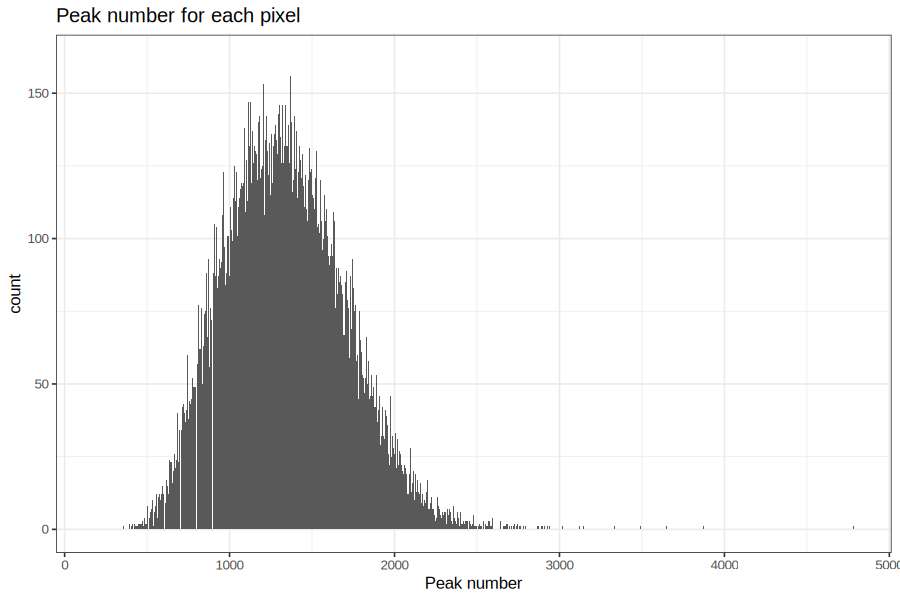

peakstats_2.png


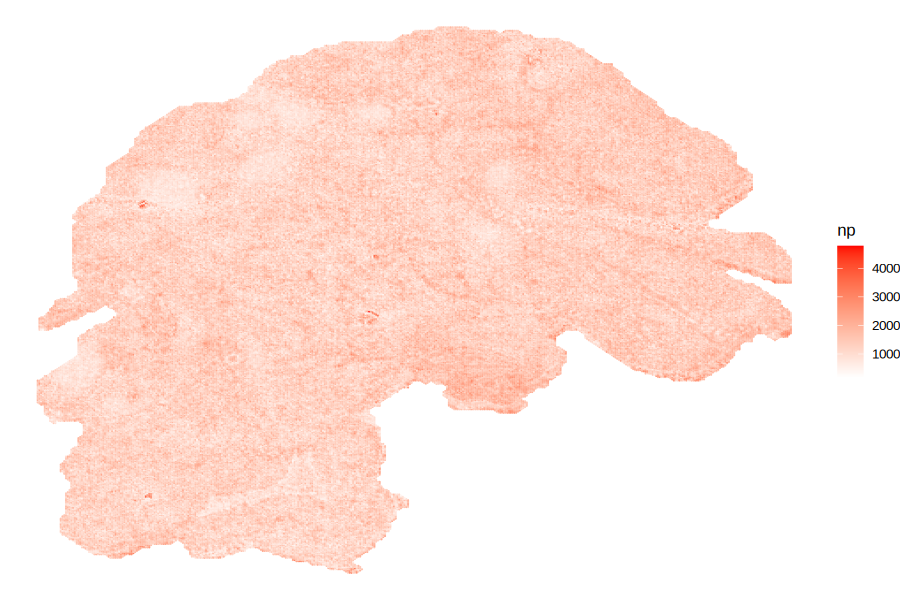

pca_segmentation.png


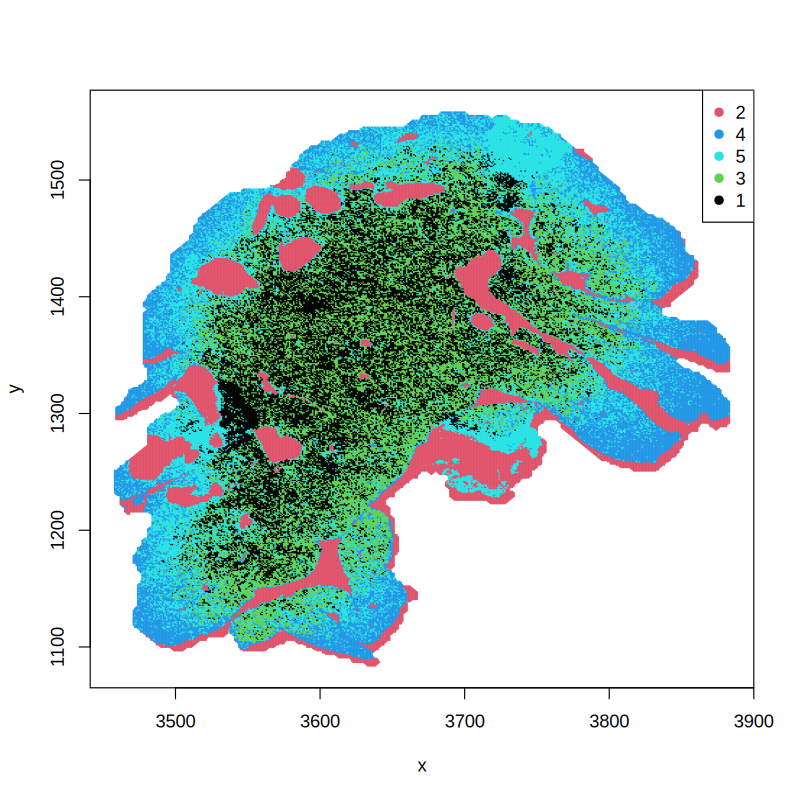

umap_segmentation.png


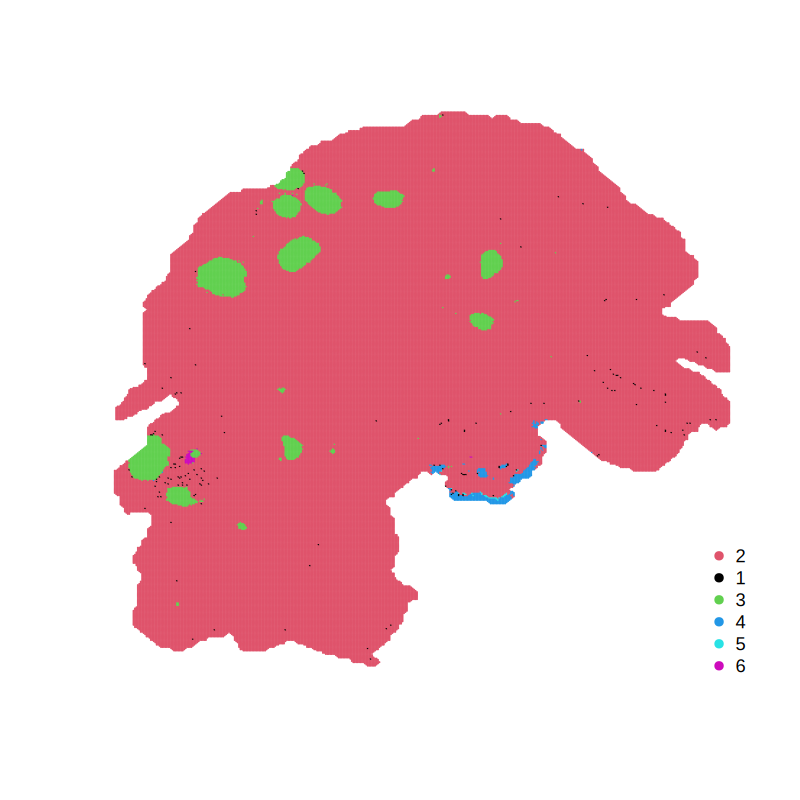

molecular_network.png


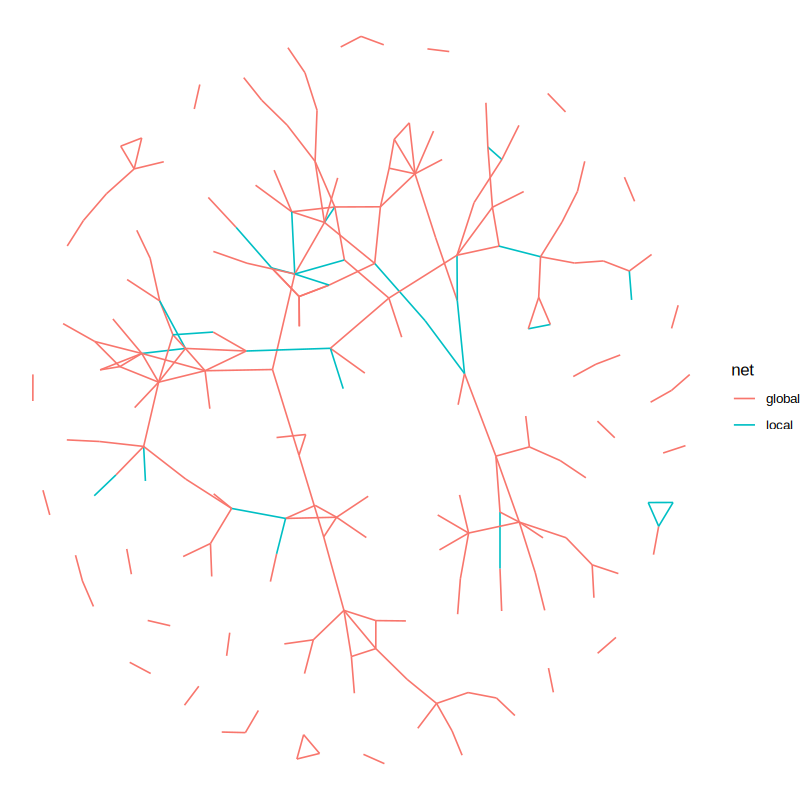

pmd2.016.png


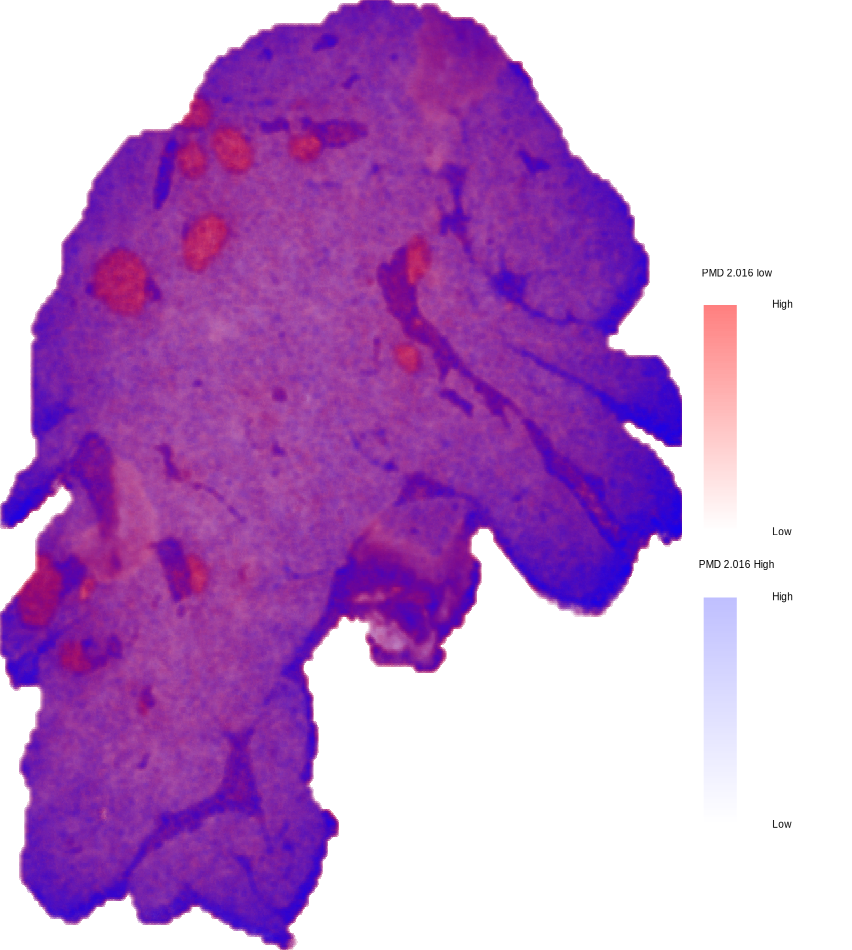


--- ion images (top abundant): 16 files ---


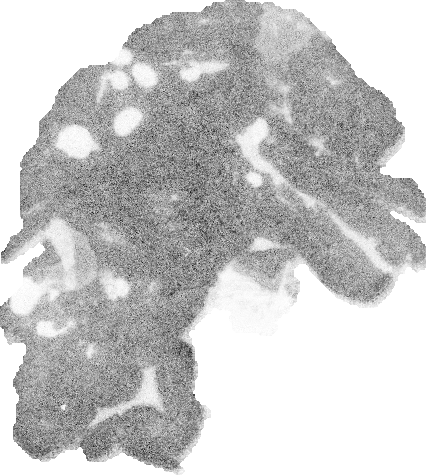

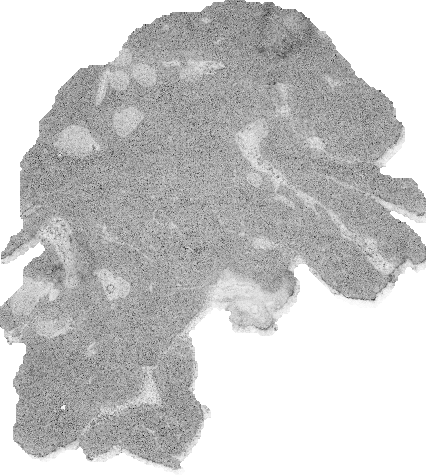

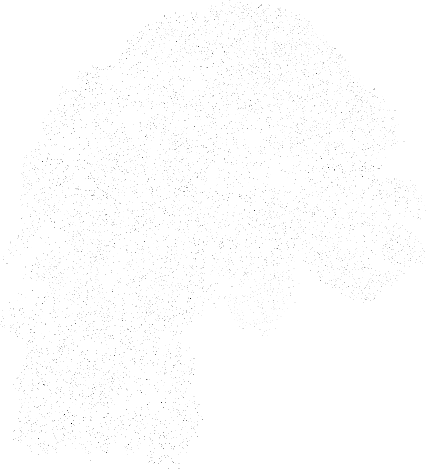

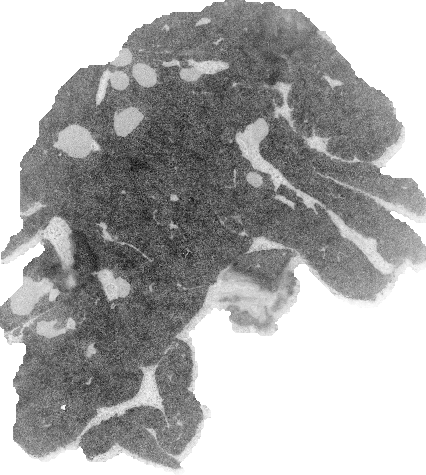

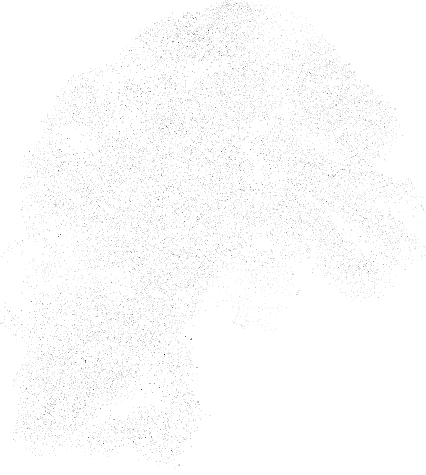

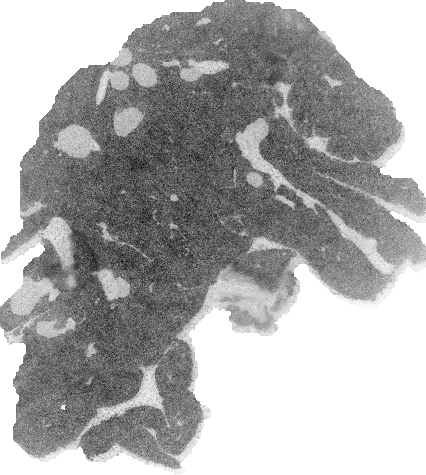

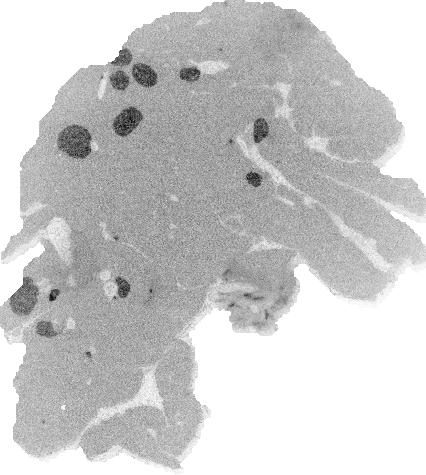


--- ion clusters (ROI): 74 files ---


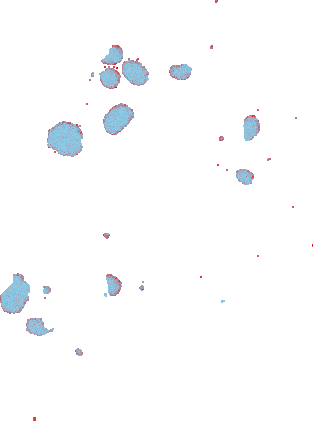

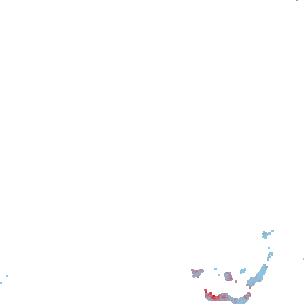

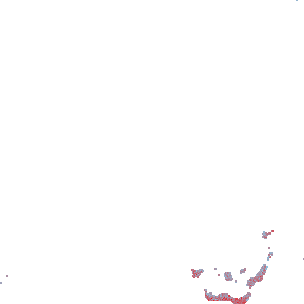

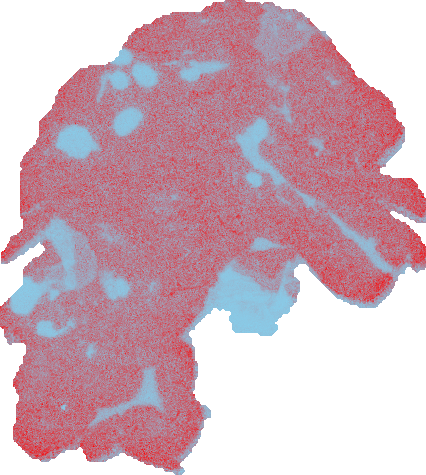

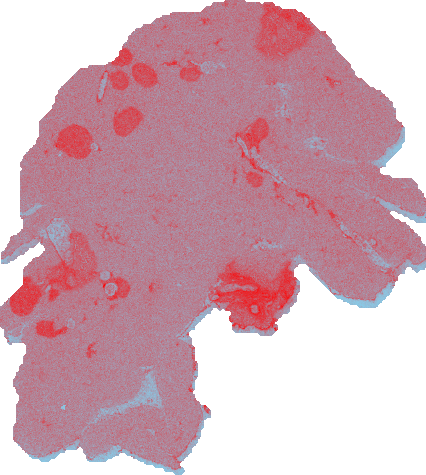

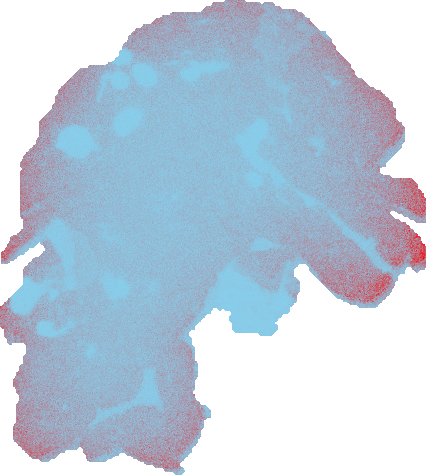

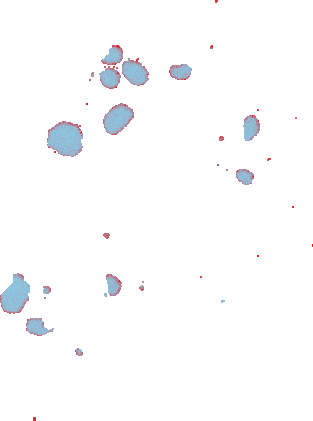


--- network node images: 5959 files ---


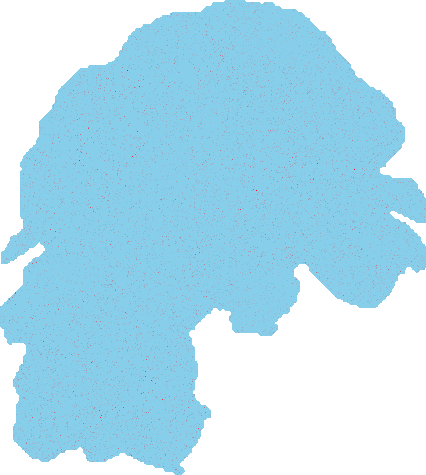

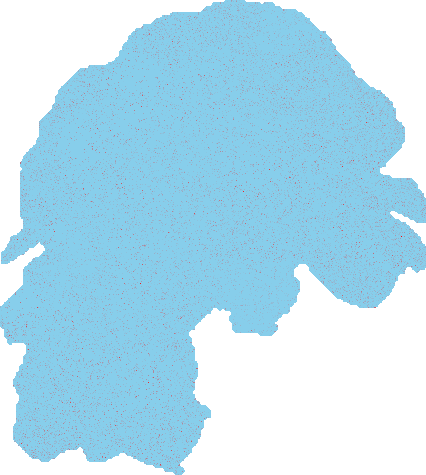

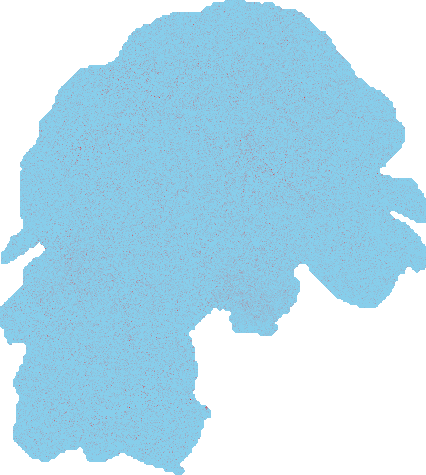

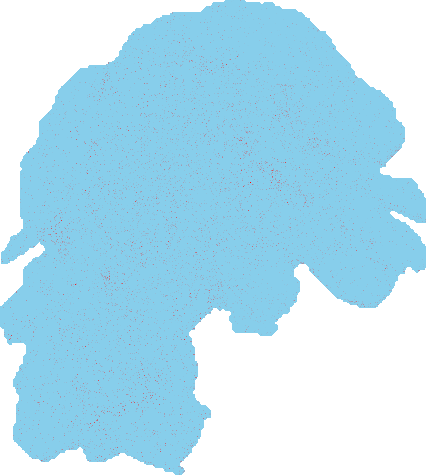

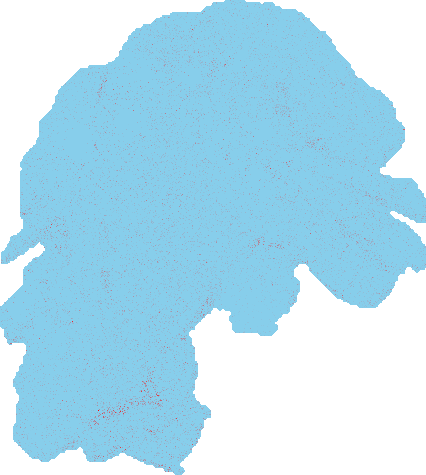

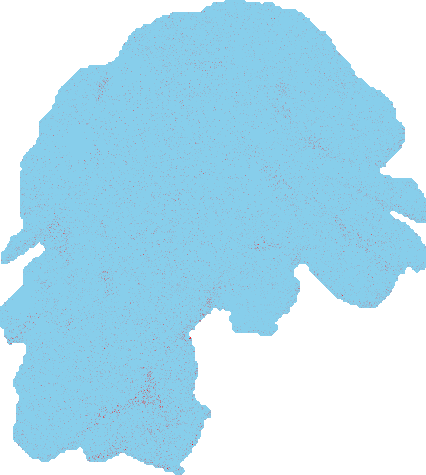

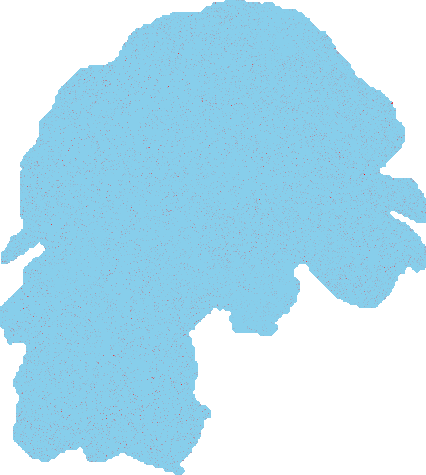

In [24]:
import os
import pandas as pd
from IPython.display import Image, display

REPO = '/content/OSSpRe'

# ---- tables ----
for f in ['refpeak.csv', 'ref2d.csv', 'ticmzccs.csv', 'annoccs.csv',
          'metaannoccs.csv', 'ioncluster.csv', 'roi_ion_cluster.csv',
          'molecular_network.csv', 'msinet.csv']:
    p = os.path.join(REPO, f)
    if os.path.exists(p):
        d = pd.read_csv(p, encoding='latin1')
        print(f'{f:24s} rows={len(d):6d} cols={d.shape[1]}')
    else:
        print(f'{f:24s} MISSING')

print('\n--- lipid annotation preview ---')
p = os.path.join(REPO, 'annoccs.csv')
if os.path.exists(p):
    d = pd.read_csv(p, encoding='latin1')
    print(d.shape)
    display(d.head(10) if len(d) else d)

# ---- top-level figures ----
print('\n--- figures ---')
for name in ['peakstats_1.png', 'peakstats_2.png', 'pca_segmentation.png',
             'umap_segmentation.png', 'molecular_network.png', 'pmd2.016.png']:
    p = os.path.join(REPO, name)
    if os.path.exists(p):
        print(name)
        display(Image(p, width=300))

# ---- image folders ----
for label, folder in [('ion images (top abundant)', REPO),
                      ('ion clusters (full sample)', os.path.join(REPO, 'fullsample')),
                      ('ion clusters (ROI)', os.path.join(REPO, 'roi')),
                      ('network node images', os.path.join(REPO, 'fig'))]:
    if not os.path.isdir(folder):
        continue
    pngs = sorted(f for f in os.listdir(folder) if f.endswith('.png'))
    if not pngs:
        continue
    print(f'\n--- {label}: {len(pngs)} files ---')
    for f in pngs[:7]:
        display(Image(os.path.join(folder, f), width=170))

## Interactive Shiny apps (optional, needs a port forward)

The two GUI tools need a browser talking to a local R process, so they are not
run inline here. To use them locally or with a tunnel:

```r
# annotation GUI
rmwf::runmzccsanno()
# network GUI (uses msinet.csv / annoccs.csv / fig/ produced above)
rmwf::runmsinet()
```

On Colab you can expose them through `google-colab-proxy`, or simply download
the csv/figures above and open them on your own machine.

## Notes and troubleshooting

- **Re-run a single step**: each step is a self-contained `Rscript`, and the
  Renv library plus the compiled C++ cache (`/content/rcpp_cache`) persist for
  the session, so re-running one step costs only that step's time.
- **Interrupted environment restore**: re-run the `Rscript` cell in step 0b.
- **`bruker_roundtrip` / step 1 fails on the EULA download**: the
  `libtimsdata.so` fetch needs network access to Bruker's server; retry the
  step, or download the library manually into `/content/bruker/`.
- **Different ROI**: widen `XRANGE`/`YRANGE` in `/content/config.R`. A larger
  ROI means proportionally more pixels to process in step 3.
- **Empty annotation / empty network**: not an error — `getanno` may find no
  database match and `generate_molecular_network` writes an empty csv by
  design.
- **UMAP skipped**: install `umap-learn` (done in step 0b) and make sure
  reticulate picks Colab's python via `RETICULATE_PYTHON`; PCA segmentation is
  unaffected and is enough for ROI selection.